# Explict EDA

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('data/billboard.csv')

### Overview

In [4]:
df.columns

Index(['song', 'artist', 'date', 'weeks_at_number_one', 'non_consecutive',
       'rating_1', 'rating_2', 'rating_3', 'overall_rating', 'divisiveness',
       ...
       'featured_in_a_then_contemporary_play', 'written_for_a_film',
       'featured_in_a_then_contemporary_film', 'written_for_a_t_v_show',
       'featured_in_a_then_contemporary_t_v_show', 'associated_with_dance',
       'topped_the_charts_by_multiple_artist', 'double_a_side',
       'eurovision_entry', 'u_s_artwork'],
      dtype='str', length=105)

In [5]:
ex = df[['song', 'artist', 'date', 'weeks_at_number_one', 'explicit', 'lyrics', 'lyrical_topic']]

In [6]:
ex['explicit'].value_counts()

explicit
0    940
1    237
Name: count, dtype: int64

In [7]:
ex.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic
0,Poor Little Fool,Ricky Nelson,1958-08-04T00:00:00Z,2,0,I used to play around with hearts.That hastene...,Lost Love
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18T00:00:00Z,5,0,NaN,Flying;Dreaming
2,Little Star,The Elegants,1958-08-25T00:00:00Z,1,0,Where are you little star.Where are you.Twinkl...,Longing for Love
3,It's All in the Game,Tommy Edwards,1958-09-29T00:00:00Z,6,0,Many a tear have to fall.But it's all in the g...,Love
4,It's Only Make Believe,Conway Twitty,1958-11-10T00:00:00Z,2,0,People see us everywhere.They think you really...,Lost Love


In [8]:
ex['year'] = ex['date'].str[:4]
ex['decade'] = (ex['year'].astype(int) // 10) * 10
ex.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade
0,Poor Little Fool,Ricky Nelson,1958-08-04T00:00:00Z,2,0,I used to play around with hearts.That hastene...,Lost Love,1958,1950
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18T00:00:00Z,5,0,NaN,Flying;Dreaming,1958,1950
2,Little Star,The Elegants,1958-08-25T00:00:00Z,1,0,Where are you little star.Where are you.Twinkl...,Longing for Love,1958,1950
3,It's All in the Game,Tommy Edwards,1958-09-29T00:00:00Z,6,0,Many a tear have to fall.But it's all in the g...,Love,1958,1950
4,It's Only Make Believe,Conway Twitty,1958-11-10T00:00:00Z,2,0,People see us everywhere.They think you really...,Lost Love,1958,1950


Note. I will need to see what I can do to look at reasons for explicit rating as it is not within our dataset

### Timeline

C:\Users\Izzy\AppData\Local\Temp\ipykernel_15860\2868086576.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  yearly.set_xticklabels(yearly.get_xticklabels(), rotation=90, size = 5)


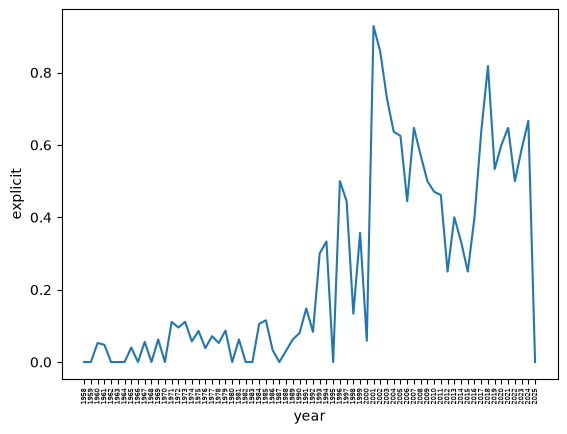

In [9]:
yearly = sns.lineplot(data=ex, x='year', y='explicit', errorbar=None)
yearly.set_xticklabels(yearly.get_xticklabels(), rotation=90, size = 5)
plt.show()

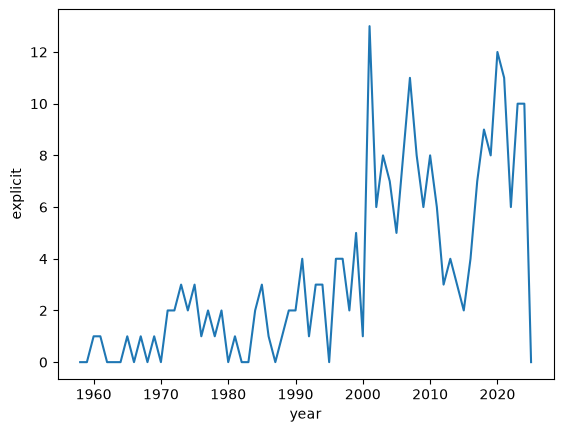

In [36]:
yearly = sns.lineplot(data=ex, x='year', y='explicit', errorbar=None, estimator=sum)
yearly.set_xticks([2,12,22,32,42,52,62])
plt.show()

### Lyrical reasoning

In [11]:
print(ex["lyrical_topic"].nunique())
ex["lyrical_topic"].value_counts()

398


lyrical_topic
Lost Love                             155
Love                                  153
Lust/Sex                              153
Longing for Love                       48
Dancing                                21
                                     ... 
Anger;Bragging                          1
Getting Back Together;Friendship        1
Lust/Sex;Partying;Bragging;Respect      1
Anger;Bragging;Fighting                 1
Love;Death;Longing for Love             1
Name: count, Length: 398, dtype: int64

In [12]:
exonly = ex[ex['explicit'] == True]
exonly.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade
36,Mr. Custer,Larry Verne,1960-10-10T00:00:00Z,1,1,That famous day in history.The men of the 7th ...,War,1960,1960
60,Big Bad John,Jimmy Dean,1961-11-06T00:00:00Z,5,1,Every morning at the mine you could see him ar...,Work;Death,1961,1960
139,(I Can't Get No) Satisfaction,The Rolling Stones,1965-07-10T00:00:00Z,4,1,I can't get no satisfaction.I can't get no sat...,Lust/Sex;Anger;Restlessness,1965,1960
187,Light My Fire,The Doors,1967-07-29T00:00:00Z,3,1,You know that it would be untrue.You know that...,Lust/Sex,1967,1960
217,Honky Tonk Women,The Rolling Stones,1969-08-23T00:00:00Z,4,1,I met a gin soaked barroom queen in Memphis.Sh...,Lust/Sex,1969,1960


In [13]:
print(exonly["lyrical_topic"].nunique())
exonly["lyrical_topic"].value_counts()

118


lyrical_topic
Lust/Sex                              56
Lost Love                             17
Lost Love;Bad Relationships           10
Bragging                               6
Lust/Sex;Dancing                       5
                                      ..
Bragging;Fame                          1
Infidelity;Lust/Sex;Empowerment        1
Anger;Bragging                         1
Lust/Sex;Partying;Bragging;Respect     1
Anger;Bragging;Fighting                1
Name: count, Length: 118, dtype: int64

### Grouping

In [14]:
# making the grouping
sexual_topic = ['Lust/Sex', 'Love', 'Lost Love', 'Masturbation', 'Infidelity', 'Bad Relationships', 'Longing for Love', 'Marriage', 'Getting Back Together']
sexual_words = ['penis', 'vagina', 'tits', 'blowjob', 'boner', 'clit', 'cum', 'pussy']
drug_alcohol_topic = ['Addiction', 'Partying']
violence_topic = ['War', 'Death', 'Fighting', 'Violence', 'Murder', 'Revenge', 'Anger', 'Bad Behavior']
profanity_slur_words = ['ass', 'balls', 'bastard', 'bitch', 'blowjob', 'boner', 'clit', 'cock', 'cum', 'cunt', 'damn', 'dick', 'dyke', 'faggot', 'fuck', 'hell', 'nigger', 'pecker', 'piss', 'pussy', 'shit', 'tits', 'twat', 'whore', 'fucker', 'motherfucker', 'fag', 'fucking', 'damnit']

#### Testing to see if code will work

In [15]:
# Testing a small group to see if this works
extest = ex.head()

In [16]:
def check_topic(list,row):
    for topic in list:
        if topic in extest.iloc[row,6]:
                return True
    return False

In [17]:
extest

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade
0,Poor Little Fool,Ricky Nelson,1958-08-04T00:00:00Z,2,0,I used to play around with hearts.That hastene...,Lost Love,1958,1950
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18T00:00:00Z,5,0,NaN,Flying;Dreaming,1958,1950
2,Little Star,The Elegants,1958-08-25T00:00:00Z,1,0,Where are you little star.Where are you.Twinkl...,Longing for Love,1958,1950
3,It's All in the Game,Tommy Edwards,1958-09-29T00:00:00Z,6,0,Many a tear have to fall.But it's all in the g...,Love,1958,1950
4,It's Only Make Believe,Conway Twitty,1958-11-10T00:00:00Z,2,0,People see us everywhere.They think you really...,Lost Love,1958,1950


In [18]:
extest.iloc[0, 6]

'Lost Love'

In [19]:
sexual_test = []
for row in range(len(extest)):
    sexual_test.append(check_topic(sexual_topic,row))

print(sexual_test)

[True, False, True, True, True]


#### Creating columns for explicit reasoning

In [20]:
def checking_topic(list,row):
    for topic in list:
        if topic in str(exonly.iloc[row,6]):
                return True
    return False

In [21]:
def checking_lyrics(list,row):
    for word in list:
        if word in str(exonly.iloc[row,5]):
                return True
    return False

In [22]:
def checking_topic_lyrics(topic_list,word_list,row):
    for topic in topic_list:
        if topic in str(exonly.iloc[row,6]):
            return True
    for word in word_list:
        if word in str(exonly.iloc[row,5]):
            return True
    return False

In [23]:
sexual = []
for row in range(len(exonly)):
    sexual.append(checking_topic_lyrics(sexual_topic,sexual_words,row))

drug_alcohol = []
for row in range(len(exonly)):
    drug_alcohol.append(checking_topic(drug_alcohol_topic,row))

violence = []
for row in range(len(exonly)):
    violence.append(checking_topic(violence_topic,row))

profanity_slur = []
for row in range(len(exonly)):
    profanity_slur.append(checking_lyrics(profanity_slur_words,row))


In [24]:
exonly['sexual'] = sexual
exonly['drug_alcohol'] = drug_alcohol
exonly['violence'] = violence
exonly['profanity_slur'] = profanity_slur

exonly.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade,sexual,drug_alcohol,violence,profanity_slur
36,Mr. Custer,Larry Verne,1960-10-10T00:00:00Z,1,1,That famous day in history.The men of the 7th ...,War,1960,1960,False,False,True,False
60,Big Bad John,Jimmy Dean,1961-11-06T00:00:00Z,5,1,Every morning at the mine you could see him ar...,Work;Death,1961,1960,False,False,True,True
139,(I Can't Get No) Satisfaction,The Rolling Stones,1965-07-10T00:00:00Z,4,1,I can't get no satisfaction.I can't get no sat...,Lust/Sex;Anger;Restlessness,1965,1960,True,False,True,False
187,Light My Fire,The Doors,1967-07-29T00:00:00Z,3,1,You know that it would be untrue.You know that...,Lust/Sex,1967,1960,True,False,False,False
217,Honky Tonk Women,The Rolling Stones,1969-08-23T00:00:00Z,4,1,I met a gin soaked barroom queen in Memphis.Sh...,Lust/Sex,1969,1960,True,False,False,False


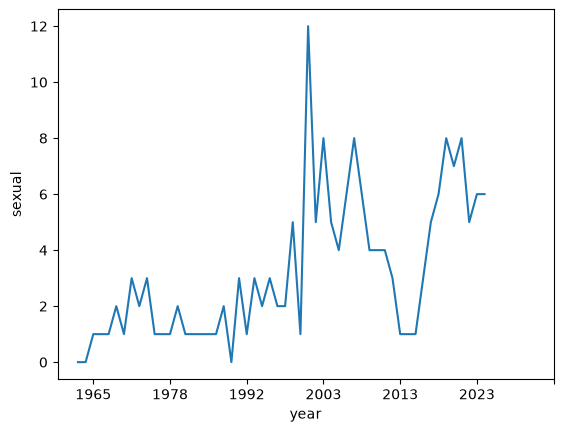

In [30]:
yearly = sns.lineplot(data=exonly, x='year', y='sexual', estimator=sum, errorbar=None)
yearly.set_xticks([2,12,22,32,42,52,62])
plt.show()

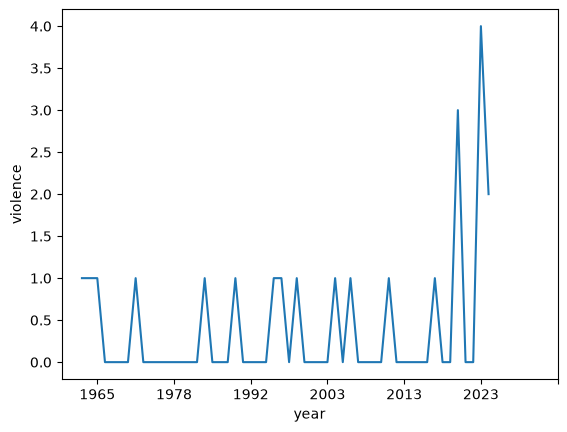

In [ ]:
yearly = sns.lineplot(data=exonly, x='year', y='drug_alcohol', estimator=sum, errorbar=None)
yearly.set_xticks([2,12,22,32,42,52,62])
plt.show()

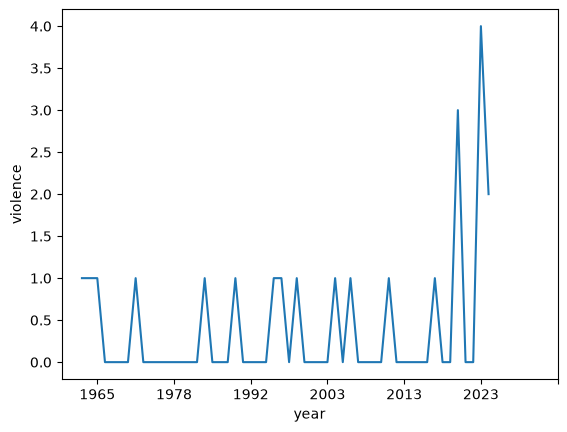

In [35]:
yearly = sns.lineplot(data=exonly, x='year', y='violence', estimator=sum, errorbar=None)
yearly.set_xticks([2,12,22,32,42,52,62])
plt.show()

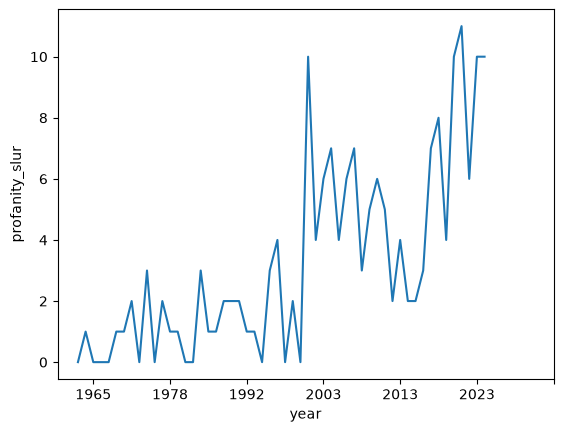

In [34]:
yearly = sns.lineplot(data=exonly, x='year', y='profanity_slur', estimator=sum, errorbar=None)
yearly.set_xticks([2,12,22,32,42,52,62])
plt.show()